<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/271756_EDA_Analitic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Ari Daniel Mendoza Enrriquez  

**Matrícula:** 271756

**Fecha:** 11 / 10 / 26

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [18]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico de una campaña. Un cliente podría aparecer en más de un contacto. |
| ¿Qué se predice? | Si el contacto terminará con una contratación del depósito (y = yes). |
| ¿Qué tipo de problema es? | Clasificación binaria ( yes o no). |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Seria antes de llamar para decidir a quién contactar y estarían disponibles los datos del cliente, contactos anteriores y los indicadores económicos conocidos en ese momento. |
| ¿Qué columnas no deberían usarse como características y por qué? | `y` es la respuesta que se intenta predecir. `duration` se conoce solo cuando termina la llamada, así que no estaría disponible al decidir a quién llamar y la columna `suscribe` que crearé después también representa a `y` y no debe usarse como entrada. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Espero que una minoría contrate el depósito, como alrededor del 10 al 15 % de los contactos.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Habria pocos NaN, pero sí respuestas unknown en datos como escolaridad, empleo, créditos y estado civil. Esperaria que sean cientos de filas en varias columnas y tal vez miles en default.

In [19]:
# B1. Reviso el tamaño, tipos y cuántos valores distintos tiene cada columna.
print('Dimensiones:', df.shape)
print('\nTipos de dato:')
print(df.dtypes.to_string())
print('\nValores únicos por columna:')
print(df.nunique().sort_values().to_string())

Dimensiones: (41188, 21)

Tipos de dato:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object

Valores únicos por columna:
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26
cons.conf.idx       26
pdays           

In [20]:
# B2. Busco NaN y el texto 'unknown' en las columnas categóricas.
print('Total de valores NaN:', df.isna().sum().sum())
conteo_unknown = (df[categoricas] == 'unknown').sum()
conteo_unknown = conteo_unknown[conteo_unknown > 0].sort_values(ascending=False)
resumen_unknown = pd.DataFrame({
    'filas': conteo_unknown,
    'porcentaje': (conteo_unknown / len(df) * 100).round(2)
})
print('\nColumnas que tienen unknown:')
print(resumen_unknown.to_string())

Total de valores NaN: 0

Columnas que tienen unknown:
           filas  porcentaje
default     8597       20.87
education   1731        4.20
housing      990        2.40
loan         990        2.40
job          330        0.80
marital       80        0.19


In [21]:
# B3. Cuento filas completamente iguales, sin borrar ninguna todavía.
print('Filas idénticas adicionales:', df.duplicated().sum())

Filas idénticas adicionales: 12


In [22]:
# B4. 999 es un código especial y comparo su frecuencia con otras columnas.
usa_999 = df['pdays'] == 999
print('pdays = 999:', usa_999.sum(), 'filas')
print('Porcentaje:', round(usa_999.mean() * 100, 2), '%')
print('\npoutcome frente a previous == 0:')
print(pd.crosstab(df['poutcome'], df['previous'] == 0).to_string())
print('\npoutcome frente a pdays == 999:')
print(pd.crosstab(df['poutcome'], usa_999).to_string())

pdays = 999: 39673 filas
Porcentaje: 96.32 %

poutcome frente a previous == 0:
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

poutcome frente a pdays == 999:
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [23]:
# B5. Verifico límites y ceros según el significado de cada variable.
print('Edad mínima y máxima:', df['age'].min(), df['age'].max())
print('Llamadas con duración cero:', (df['duration'] == 0).sum())
print('campaign mínimo y máximo:', df['campaign'].min(), df['campaign'].max())
print('previous negativo:', (df['previous'] < 0).sum())

Edad mínima y máxima: 17 98
Llamadas con duración cero: 4
campaign mínimo y máximo: 1 56
previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

El conjunto tiene 41,188 contactos y no aparecen NaN, pero sí valores unknown que son 8,597 en default (20.87 %), 1,731 en education (4.20 %) y 990 tanto en housing como en loan (2.40 % cada una), etc.
Pensé que serían menos en la mayoría, en default sí resultaron miles. También hay 12 filas completamente iguales, pero sin un identificador de contacto, asi que no puedo asegurar que sean registros repetidos por error.
Hay 39,673 filas (96.32 %) con pdays = 999, según el diccionario es un código especial y no 999 días reales. previous = 0 coincide con poutcome = nonexistent, pero 4,110 filas tienen a la vez poutcome = failure y pdays = 999, así que conviene revisar cómo se registra esa fecha antes de interpretar ambos campos juntos.
La edad va de 17 a 98 años, hay 4 llamadas de duración cero, campaign va de 1 a 56 y no hay valores negativos en previous. La edad alta o muchas llamadas pueden ser casos reales, pero su interpretación depende del significado de cada variable.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

Mantendría unknown de default como una categoría separada. Son 8,597 filas, el 20.87 % del conjunto y borrarlas quitaría demasiados datos. Más adelante comprobaría si esa categoría sirve y aplicaría el mismo tratamiento al conjunto de prueba.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué?

Al usar stratify=df['y'], espero que entrenamiento y prueba tengan prácticamente el mismo porcentaje de contrataciones, aunque no sea idéntico hasta los decimales.

In [24]:
# C1. Separo entrenamiento y prueba conservando la proporción de y.
entrenamiento, prueba = train_test_split(
    df, test_size=0.2, stratify=df['y'], random_state=42
)
ent = entrenamiento.copy()
ent['suscribe'] = (ent['y'] == 'yes').astype(int)

print('Entrenamiento:', entrenamiento.shape)
print('Prueba:', prueba.shape)
print('Contratación en entrenamiento:',
      round(ent['suscribe'].mean() * 100, 2), '%')
print('Contratación en prueba:',
      round((prueba['y'] == 'yes').mean() * 100, 2), '%')

Entrenamiento: (32950, 21)
Prueba: (8238, 21)
Contratación en entrenamiento: 11.27 %
Contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [25]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

Quedaron 32,950 contactos en entrenamientoy 8,238 para prueba, la contratación fue de 11.27 % y 11.26 % al redondear a dos decimales. La diferencia es mínima, asi que coincide con lo que esperaba de una división estratificada.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?

Si aproximadamente entre 10 y 15 % contrata, responder siempre no tendría una exactitud cercana a 85–90 %, aun sin detectar a quienes sí contratan.

     clientes  porcentaje
y                        
no      29238       88.73
yes      3712       11.27
Razón no / yes: 7.88
Exactitud de contestar siempre no: 88.73 %


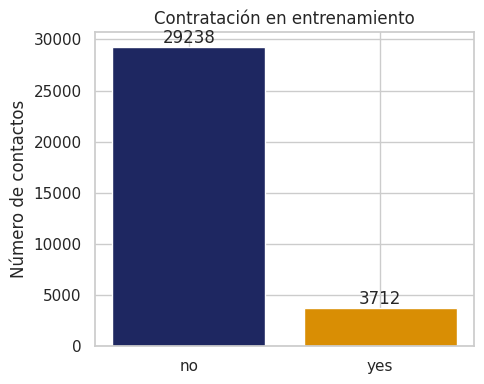

In [26]:
# D1. Calculo los tamaños de clase solo con entrenamiento.
conteos = ent['y'].value_counts()
porcentajes = (ent['y'].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({'clientes': conteos, 'porcentaje': porcentajes}).to_string())
print('Razón no / yes:', round(conteos['no'] / conteos['yes'], 2))
print('Exactitud de contestar siempre no:',
      round(conteos['no'] / len(ent) * 100, 2), '%')

# La gráfica permite ver la diferencia entre las clases.
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(['no', 'yes'], [conteos['no'], conteos['yes']],
                color=[AZUL, NARANJA])
ax.bar_label(barras)
ax.set_ylabel('Número de contactos')
ax.set_title('Contratación en entrenamiento')
plt.tight_layout()
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

En entrenamiento hay 29,238 no (88.73 %) y 3,712 yes (11.27 %), una razón de 7.88 a 1. Mi predicción del porcentaje y de la exactitud quedó cerca, ya que responder siempre no acertaría el 88.73 %, pero fallaría en todos los casos yes. Por eso la exactitud sola no bastaría, también revisaría recuperación, precisión y F1 de la clase yes.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?

Espero diferencias en la duración de la llamada y en algunos indicadores económicos. La edad quizá cambie poco entre quienes contratan y quienes no.

Medianas por clase:
y                    no      yes
age               38.00    37.00
duration         164.00   448.00
campaign           2.00     2.00
pdays            999.00   999.00
previous           0.00     0.00
emp.var.rate       1.10    -1.80
cons.price.idx    93.92    93.20
cons.conf.idx    -41.80   -40.40
euribor3m          4.86     1.27
nr.employed     5195.80  5099.10


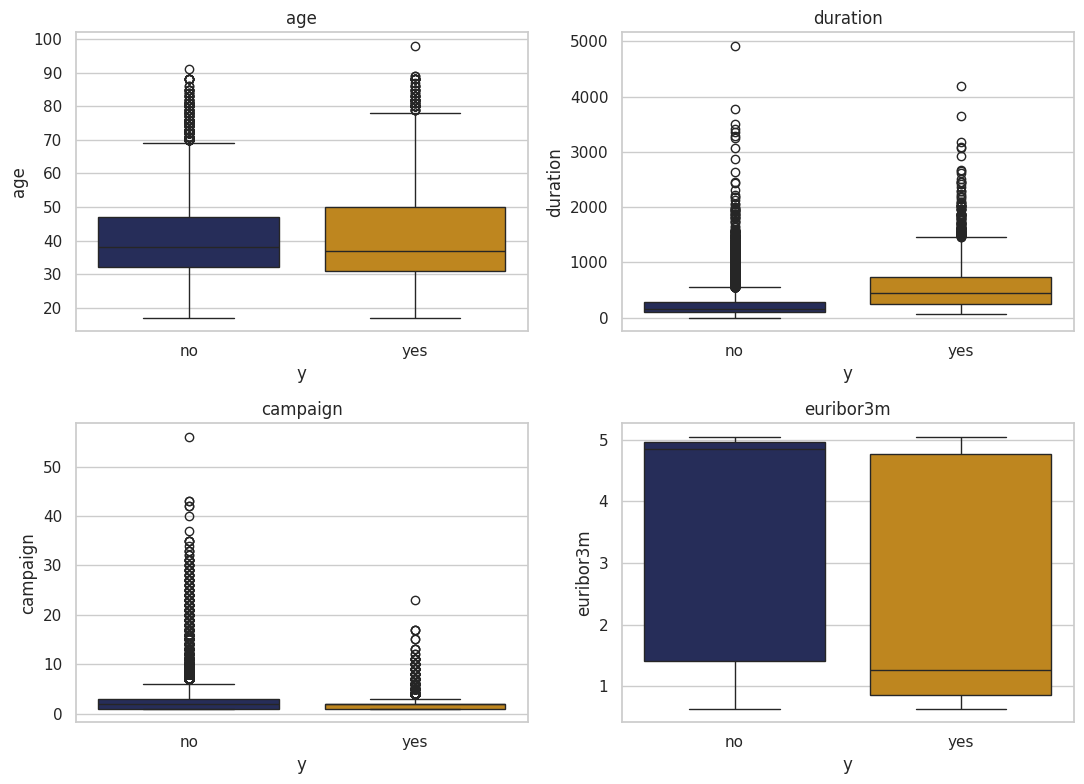

In [27]:
# D2. Uso medianas porque algunas variables tienen valores extremos.
medianas = ent.groupby('y')[numericas].median().T
print('Medianas por clase:')
print(medianas.round(2).to_string())

# Comparo cuatro variables con un diagrama de caja por clase.
variables_grafica = ['age', 'duration', 'campaign', 'euribor3m']
fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
for ax, columna in zip(ejes.flat, variables_grafica):
    sns.boxplot(data=ent, x='y', y=columna, hue='y',
                order=['no', 'yes'], palette=COLORES_CLASE,
                legend=False, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

Las medianas de duration son 448 segundos para yes y 164 para no, euribor3m es 1.266 frente a 4.857 y emp.var.rate es −1.8 frente a 1.1, se separan bastante a los grupos en esta muestra. La edad cambia poco: 37 frente a 38 años.
Esto coincide con mi predicción y la diferencia de duration es clara, pero se conoce después de la llamada y no la usaría para decidir a quién llamar.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?

Creo que duration y campaign tendrán muchos valores fuera de los límites de Tukey porque algunas llamadas y campañas son más largas que otras. También podría aparecer pdays por el código 999.

In [28]:
# D3. Calculo cuartiles y límites de Tukey solo con ent.
q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1
limite_inferior = q1 - 1.5 * ric
limite_superior = q3 + 1.5 * ric
fuera = ent[numericas].lt(limite_inferior) | ent[numericas].gt(limite_superior)
resumen_atipicos = pd.DataFrame({
    'inferior': limite_inferior,
    'superior': limite_superior,
    'fuera_de_limites': fuera.sum()
})
print(resumen_atipicos.round(2).to_string())

                inferior  superior  fuera_de_limites
age                 9.50     69.50               368
duration         -221.00    643.00              2366
campaign           -2.00      6.00              1916
pdays             999.00    999.00              1226
previous            0.00      0.00              4534
emp.var.rate       -6.60      6.20                 0
cons.price.idx     91.70     95.37                 0
cons.conf.idx     -52.15    -26.95               359
euribor3m          -4.08     10.39                 0
nr.employed      4905.60   5421.60                 0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.

No eliminaría ninguna fila. En entrenamiento, Tukey marca 2,366 valores de duration y 1,916 de campaign, las llamadas largas y varios intentos pueden ser reales. Tampoco borraría las 1,226 filas marcadas en pdays ni las 4,534 de previous, sus cuartiles hacen que contactos anteriores válidos parezcan atípicos, y 999 es un código especial. En age hay 368 valores fuera del límite superior de 69.5 años, pero el máximo de 98 es posible. cons.conf.idx marca 359 y los otros indicadores económicos no marcan ninguno. Revisaría su significado, dependiendo del modelo, transformaría o escalaría algunas variables usando solo entrenamiento. duration quedaría fuera de un modelo que predice antes de llamar.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?

Creo que np.log1p reducirá más la asimetría de campaign que la raíz cuadrada, porque comprime más los valores grandes.

Asimetría:
          original  raiz_cuadrada  logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35


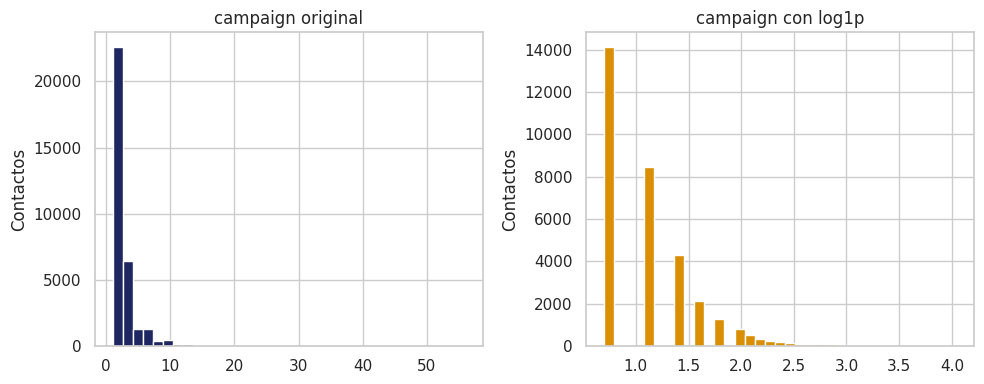

In [29]:
# D4. Comparo la asimetría original con dos transformaciones.
variables_asimetria = ['age', 'duration', 'campaign']
asimetrias = pd.DataFrame({
    'original': ent[variables_asimetria].skew(),
    'raiz_cuadrada': np.sqrt(ent[variables_asimetria]).skew(),
    'logaritmo': np.log1p(ent[variables_asimetria]).skew()
})
print('Asimetría:')
print(asimetrias.round(2).to_string())

# Muestro campaign antes y después del logaritmo, que reduce más su asimetría.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].hist(ent['campaign'], bins=35, color=AZUL, edgecolor='white')
ejes[0].set_title('campaign original')
ejes[1].hist(np.log1p(ent['campaign']), bins=35,
             color=NARANJA, edgecolor='white')
ejes[1].set_title('campaign con log1p')
for ax in ejes:
    ax.set_ylabel('Contactos')
plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.

Para campaign la asimetría baja de 4.74 a 2.16 con raíz cuadrada y a 1.35 con log1p, como esperaba. En age baja de 0.76 a 0.43 con raíz y a 0.13 con logaritmo, podría probar el logaritmo si el modelo lo necesita, pero la edad original no es muy asimétrica. En duration baja de 3.33 a 1.20 con raíz y pasa a −0.43 con logaritmo. La gráfica de campaign muestra que el logaritmo reduce la cola derecha. Podria considerar log1p para campaign en un modelo sensible a la escala y comprobándolo después, no transformaría duration para usarla antes de llamar porque en ese momento no se conoce.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?

Espero que poutcome = success tenga una tasa alta, pues ya hubo una contratación previa y housing, loan y day_of_week separarán poco las clases.

In [30]:
# E1. Reviso cuántas categorías tiene cada variable y la tasa general.
print('Categorías por variable:')
print(ent[categoricas].nunique().sort_values().to_string())
tasa_global = ent['suscribe'].mean() * 100
print('\nTasa global de contratación:', round(tasa_global, 2), '%')

Categorías por variable:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12

Tasa global de contratación: 11.27 %


In [31]:
# E2. Paso a formato largo para calcular una tasa para cada categoría.
largo = ent[categoricas].astype(str).assign(suscribe=ent['suscribe']).melt(
    id_vars='suscribe', var_name='variable', value_name='categoria'
)
tasas = largo.groupby(['variable', 'categoria'])['suscribe'].agg(
    clientes='count', tasa='mean'
)
tasas['tasa'] = tasas['tasa'] * 100

print('12 categorías con mayor tasa:')
print(tasas.sort_values('tasa', ascending=False).head(12).round(2).to_string())
print('\n8 categorías con menor tasa:')
print(tasas.sort_values('tasa', ascending=False).tail(8).round(2).to_string())
for columna in ['default', 'housing', 'loan', 'day_of_week']:
    print('\n', columna, sep='')
    print(tasas.loc[columna].round(2).to_string())

12 categorías con mayor tasa:
                      clientes   tasa
variable  categoria                  
poutcome  success         1105  64.89
month     dec              143  50.35
          mar              436  49.77
          sep              464  44.61
          oct              587  43.27
job       student          711  30.52
          retired         1366  25.48
month     apr             2085  20.48
education illiterate        16  18.75
marital   unknown           65  16.92
education unknown         1397  14.82
contact   cellular       20908  14.70

8 categorías con menor tasa:
                       clientes  tasa
variable  categoria                  
education basic.6y         1865  8.36
job       services         3196  7.95
education basic.9y         4826  7.65
job       blue-collar      7441  6.92
month     may             11011  6.35
contact   telephone       12042  5.30
default   unknown          6940  5.20
          yes                 3  0.00

default
           clientes

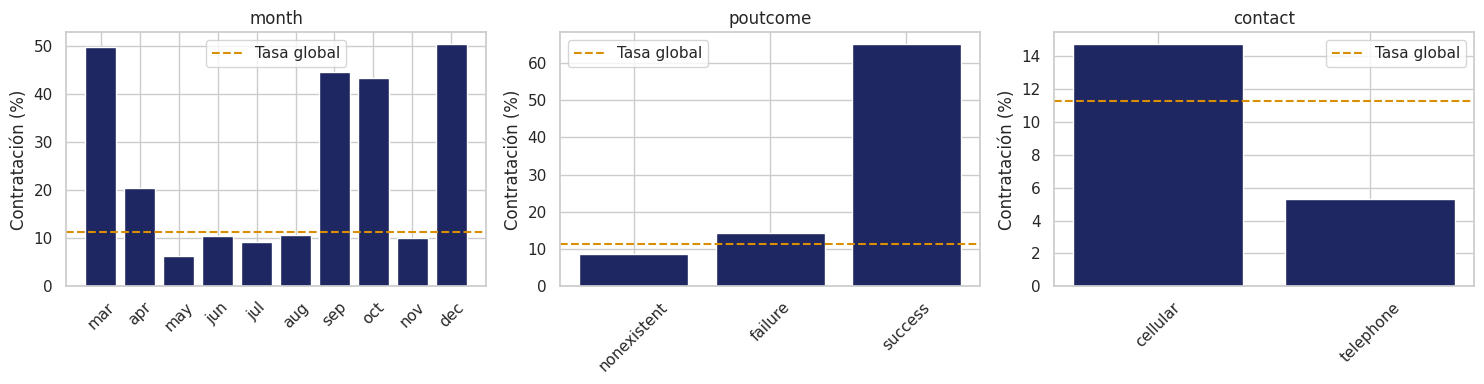

In [32]:
# E3. Ordeno los meses cronológicamente y marco la tasa global.
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul',
               'aug', 'sep', 'oct', 'nov', 'dec']
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ordenes = [orden_meses, ['nonexistent', 'failure', 'success'],
           ['cellular', 'telephone']]
for ax, columna, orden in zip(ejes, ['month', 'poutcome', 'contact'], ordenes):
    valores = tasas.loc[columna].reindex(orden)['tasa']
    ax.bar(orden, valores, color=AZUL)
    ax.axhline(tasa_global, color=NARANJA, linestyle='--',
               label='Tasa global')
    ax.set_title(columna)
    ax.set_ylabel('Contratación (%)')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.

La tasa general es 11.27 %. Entre las categorías altas está poutcome = success, 64.89 % con 1,105 contactos. También aparecen diciembre (50.35 %, 143) y marzo (49.77 %, 436), aunque tienen menos contactos que mayo (6.35 %, 11,011). Entre las bajas, default = unknown tiene 5.20 % con 6,940 contactos y contact = telephone 5.30 % con 12,042. default = yes sale en 0 %, pero tiene solo 3 contactos y no alcanza para sacar una conclusión firme.
Como esperaba, housing y loan casi no separan las clases, sus tasas rondan el 11 %. day_of_week varía de 10.25 % a 12.00 %, bastante menos que poutcome o month. El mes y el medio de contacto también podrían reflejar cambios de campaña a lo largo del tiempo.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?

default = unknown tiene 5.20 % de contratación en 6,940 contactos, frente a 12.89 % en los 26,007 con default = no. Eso sugiere que el desconocimiento del dato puede tener información propia, asi que no lo reemplazaría por no. Cuidaría las categorías pequeñas: default = yes solo tiene 3 contactos y education = illiterate tiene 16, por lo que sus tasas de 0 % y 18.75 % pueden cambiar mucho con pocos casos.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados?

Espero una relación alta entre emp.var.rate, euribor3m y nr.employed, porque todos están relacionados con el contexto económico.

                emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
emp.var.rate            1.00            0.77           0.20       0.97         0.91
cons.price.idx          0.77            1.00           0.06       0.69         0.52
cons.conf.idx           0.20            0.06           1.00       0.28         0.10
euribor3m               0.97            0.69           0.28       1.00         0.94
nr.employed             0.91            0.52           0.10       0.94         1.00


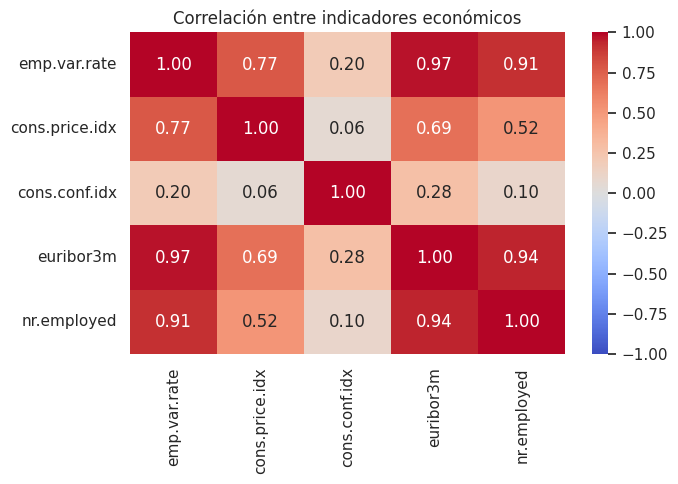

In [33]:
# F1. El mapa de calor muestra qué indicadores económicos se mueven juntos.
correlaciones = ent[macro].corr()
print(correlaciones.round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación entre indicadores económicos')
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican.

Los pares más correlacionados son emp.var.rate con euribor3m (0.97), euribor3m con nr.employed (0.95) y emp.var.rate con nr.employed (0.91). Pueden dar información parecida y causar colinealidad en algunos modelos. Probaría conservar o retirar alguna de ellas según el modelo y la validación, usando solo entrenamiento para decidirlo.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [34]:
# F2. Comparo la duración de las llamadas según el resultado.
print(ent.groupby('y')['duration'].describe().round(2).to_string())

       count    mean     std   min    25%    50%    75%     max
y                                                              
no   29238.0  221.15  208.30   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.40  397.49  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar?

No incluiría duration si el modelo se utilizará antes de llamar. Su mediana es de 448 segundos en contactos con yes y 164 con no, parece muy útil, pero la duración se conoce solo al terminar la llamada e incluirla daría al modelo información que no tendrá al tomar la decisión y haría engañosa su evaluación.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?

La división aleatoria mezcla contactos de 2008 a 2010 en entrenamiento y prueba. Si el modelo se usará para campañas futuras, podría estar aprendiendo patrones económicos de fechas posteriores a algunas filas de prueba y la evaluación resultar demasiado optimista. Para evaluar ese uso, separaría por fecha: entrenar con contactos anteriores y probar con los posteriores. El archivo viene ordenado por fecha, así que habría que conservar ese orden y evitar cualquier transformación calculada con el periodo futuro.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| duration: mediana de 448 s en yes y 164 s en no, se conoce después de llamar. | Excluirla de las entradas si se decide a quién llamar antes del contacto. | Preprocesamiento |
| default = unknown: 8,597 filas (20.87 %) en total, en entrenamiento su tasa es 5.20 % frente a 12.89 % para no. | Conservar unknown como categoría y verificar su utilidad con validación.| Preprocesamiento y modelos |
| Solo 3,712 de 32,950 contactos de entrenamiento son yes (11.27 %), contestar siempre no da 88.73 % de exactitud. | Mantener la estratificación y evaluar precisión, recuperación y F1 para yes, además de la exactitud. | Evaluación |
| pdays = 999 aparece en 39,673 filas (96.32 %), 4,110 también tienen poutcome = failure. | Tratar 999 como código especial y revisar su significado conjunto con poutcome antes de recodificarlo.| Preprocesamiento |
| emp.var.rate y euribor3m correlacionan 0.97, euribor3m y nr.employed, 0.95. | Evaluar redundancia al elegir características para modelos sensibles a colinealidad. | Preprocesamiento y modelos |
| campaign tiene asimetría de 4.74, con log1p baja a 1.35. | Probar log1p de campaign para modelos sensibles a escala, ajustándolo solo con entrenamiento. | Preprocesamiento y modelos |
| Tukey marca 4,534 casos en previous y 1,226 en pdays, variables con muchos ceros y con el código 999. | No eliminarlos por el conteo de atípicos, revisar la codificación y conservar su significado. | Preprocesamiento |
| poutcome = success tiene 64.89 % de contratación (1,105 contactos), default = yes solo tiene 3. | Explorar el antecedente de campaña y evitar conclusiones fuertes de categorías pequeñas.| Modelos y evaluación |
| Los datos cubren 2008–2010 y los indicadores económicos cambian con el tiempo. | Comparar la partición aleatoria actual con una evaluación que respete el orden temporal para uso futuro. | Evaluación |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento?

Usé el conjunto total df en A y B para definir qué representa cada fila, revisar tipos, unknown, duplicados, rangos y la relación entre pdays, previous y poutcome. Son verificaciones de estructura y calidad, sin relacionar características con y ni ajustar transformaciones. Después hice la división estratificada y usé solo ent para las partes D, E y F: tasas por clase, medianas, límites de Tukey, asimetría y correlaciones. Las decisiones de la hoja G se basan en esos resultados y no exploré las características de prueba.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?

 Si mirara las tasas de contratación de cada mes también en prueba, podría decidir conservar solo los meses que allí parecen más útiles y eso adaptaría la selección de variables a los datos reservados para evaluar. La puntuación final podría verse mejor de lo que sería con contactos realmente nuevos, por eso la decisión se toma con entrenamiento y luego se prueba sin reajustarla con el conjunto de prueba.